# Binding Affinity Prediction — Comparative Pipeline
Compares two dataset versions (previous vs newest), evaluates three models with full metrics, finds the optimal iptm threshold, then cross-validates and tunes the best model.


## 0. Dependencies

In [ ]:
# !pip install -qqq pandas numpy scikit-learn xgboost shap matplotlib seaborn joblib


## 1. Configuration

In [3]:
# ── Update these two paths before running ───────────────────────────────────
PREV_CSV   = "combined_20k.csv"   # older / smaller dataset
NEW_CSV    = "combined_30k.csv"   # newer / larger dataset
# ─────────────────────────────────────────────────────────────────────────────

TARGET_COL    = "neg_log10_affinity_M"   # switch to "affinity_Kd_nM" if preferred
IPTM_DEFAULT  = 0.70                     # starting threshold; sweep will refine this
RANDOM_SEED   = 42
TEST_SIZE     = 0.20
IPTM_SWEEP_STEP = 0.1                  # granularity of threshold search
MIN_SAMPLES   = 100                      # skip thresholds that leave fewer rows than this


## 2. Imports & Shared Helpers
All model definitions, preprocessing, and metric logic live here — used by every subsequent section.

In [26]:
import warnings, joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.ensemble         import RandomForestRegressor
from sklearn.linear_model     import Ridge
from sklearn.preprocessing    import StandardScaler
from sklearn.pipeline         import Pipeline
from sklearn.impute           import SimpleImputer
from sklearn.model_selection  import (train_test_split, cross_validate,
                                       RandomizedSearchCV)
from sklearn.metrics          import (r2_score, mean_absolute_error,
                                       mean_squared_error, roc_auc_score,
                                       precision_score, recall_score, f1_score)
import xgboost as xgb

# ── Feature sets ────────────────────────────────────────────────────────────
PHYSCHEM_FEATURES = [
    "molecular_weight", "logP", "num_h_donors", "num_h_acceptors",
    "num_rotatable_bonds", "tpsa", "num_rings", "num_aromatic_rings",
    "num_atoms", "num_heavy_atoms", "formal_charge"
]
DOCKING_FEATURES = ["score", "total", "vdw", "elec", "desolv", "bsa"]
FEATURES = PHYSCHEM_FEATURES + DOCKING_FEATURES

MODEL_COLORS = {"Ridge": "#4C72B0", "Random Forest": "#55A868", "XGBoost": "#DD8452"}
METRIC_COLS  = ["R2", "MAE", "RMSE", "AUC_ROC", "Precision", "Recall", "F1"]

# ── Load + filter + impute ───────────────────────────────────────────────────
def load_dataset(path, iptm_thresh=IPTM_DEFAULT):
    df = pd.read_csv(path, sep=None, engine="python")
    df = df[
        (df["iptm"] >= iptm_thresh) &        # confident pose
        (df["bsa"].notna()) &          # BSA was actually computed
        (df["bsa"] > 0) &              # ligand genuinely buried
        (df["score"] < 0) &            # negative docking score (favourable)
        (df["molecular_weight"] <= 900) # exclude likely peptides/macrocycles
    ]
    df = df[FEATURES + [TARGET_COL]].dropna(subset=[TARGET_COL])
    imp = SimpleImputer(strategy="median")
    X   = pd.DataFrame(imp.fit_transform(df[FEATURES]), columns=FEATURES)
    y   = df[TARGET_COL].values
    return X, y, imp

# ── Model factory (fresh instances every call) ───────────────────────────────
def make_models():
    return {
        "Ridge": Pipeline([
            ("scaler", StandardScaler()),
            ("model",  Ridge(alpha=1.0))
        ]),
        "Random Forest": RandomForestRegressor(
            n_estimators=300, max_features="sqrt",
            n_jobs=-1, random_state=RANDOM_SEED
        ),
        "XGBoost": xgb.XGBRegressor(
            n_estimators=500, learning_rate=0.05, max_depth=6,
            subsample=0.8, colsample_bytree=0.8,
            n_jobs=-1, random_state=RANDOM_SEED, verbosity=0
        )
    }

# ── Full metric suite ────────────────────────────────────────────────────────
def compute_metrics(y_true, y_pred):
    """Regression metrics + binarised classification metrics (split at median)."""
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    med  = np.median(y_true)
    yb_t = (y_true >= med).astype(int)
    yb_p = (y_pred >= med).astype(int)
    return dict(
        R2        = r2,
        MAE       = mae,
        RMSE      = rmse,
        AUC_ROC   = roc_auc_score(yb_t, y_pred) if len(np.unique(yb_t)) > 1 else np.nan,
        Precision = precision_score(yb_t, yb_p, zero_division=0),
        Recall    = recall_score(yb_t, yb_p, zero_division=0),
        F1        = f1_score(yb_t, yb_p, zero_division=0),
    )

# ── Train all models, return metrics + predictions ───────────────────────────
def train_and_evaluate(X, y):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE,
                                               random_state=RANDOM_SEED)
    models  = make_models()
    results = {}
    for name, mdl in models.items():
        mdl.fit(X_tr, y_tr)
        preds = mdl.predict(X_te)
        results[name] = {"model": mdl, "preds": preds,
                         "y_test": y_te, **compute_metrics(y_te, preds)}
    return results

print("Helpers loaded.")


Helpers loaded.


## 3. Load Datasets & Compare Models
Train all three models on both the previous and newest CSV using the default iptm threshold, then compare every metric side by side.

In [27]:
print(f"Loading datasets with iptm ≥ {IPTM_DEFAULT} ...")
X_prev, y_prev, imp_prev = load_dataset(PREV_CSV)
X_new,  y_new,  imp_new  = load_dataset(NEW_CSV)
print(f"  Previous ({PREV_CSV}): {len(X_prev):,} samples")
print(f"  Newest   ({NEW_CSV}): {len(X_new):,} samples")

print("\nTraining models on both datasets...")
res_prev = train_and_evaluate(X_prev, y_prev)
res_new  = train_and_evaluate(X_new,  y_new)
print("Done.")


Loading datasets with iptm ≥ 0.7 ...
  Previous (combined_20k.csv): 17,112 samples
  Newest   (combined_30k.csv): 25,681 samples

Training models on both datasets...
Done.


In [28]:
# ── Metrics table ─────────────────────────────────────────────────────────
label_prev = PREV_CSV.replace(".csv", "")
label_new  = NEW_CSV.replace(".csv", "")

rows = []
for name in res_prev:
    rows.append({"Model": name, "Dataset": label_prev,
                 **{m: res_prev[name][m] for m in METRIC_COLS}})
    rows.append({"Model": name, "Dataset": label_new,
                 **{m: res_new[name][m] for m in METRIC_COLS}})

compare_df = pd.DataFrame(rows).set_index(["Model", "Dataset"])
print("=== Dataset Comparison — All Metrics ===")
display(compare_df.round(4))


=== Dataset Comparison — All Metrics ===


R2     MAE    RMSE  AUC_ROC  Precision  \
Model         Dataset                                                    
Ridge         combined_20k  0.2851  1.2873  1.6200   0.7689     0.7328   
              combined_30k  0.2113  1.2417  1.5609   0.7149     0.6512   
Random Forest combined_20k  0.4781  1.0840  1.3842   0.8347     0.7531   
              combined_30k  0.4657  1.0060  1.2847   0.8309     0.7385   
XGBoost       combined_20k  0.4497  1.1142  1.4214   0.8235     0.7422   
              combined_30k  0.4263  1.0455  1.3312   0.8106     0.7201   

                            Recall      F1  
Model         Dataset                       
Ridge         combined_20k  0.6536  0.6910  
              combined_30k  0.6678  0.6594  
Random Forest combined_20k  0.7535  0.7533  
              combined_30k  0.7757  0.7566  
XGBoost       combined_20k  0.7518  0.7470  
              combined_30k  0.7606  0.7398

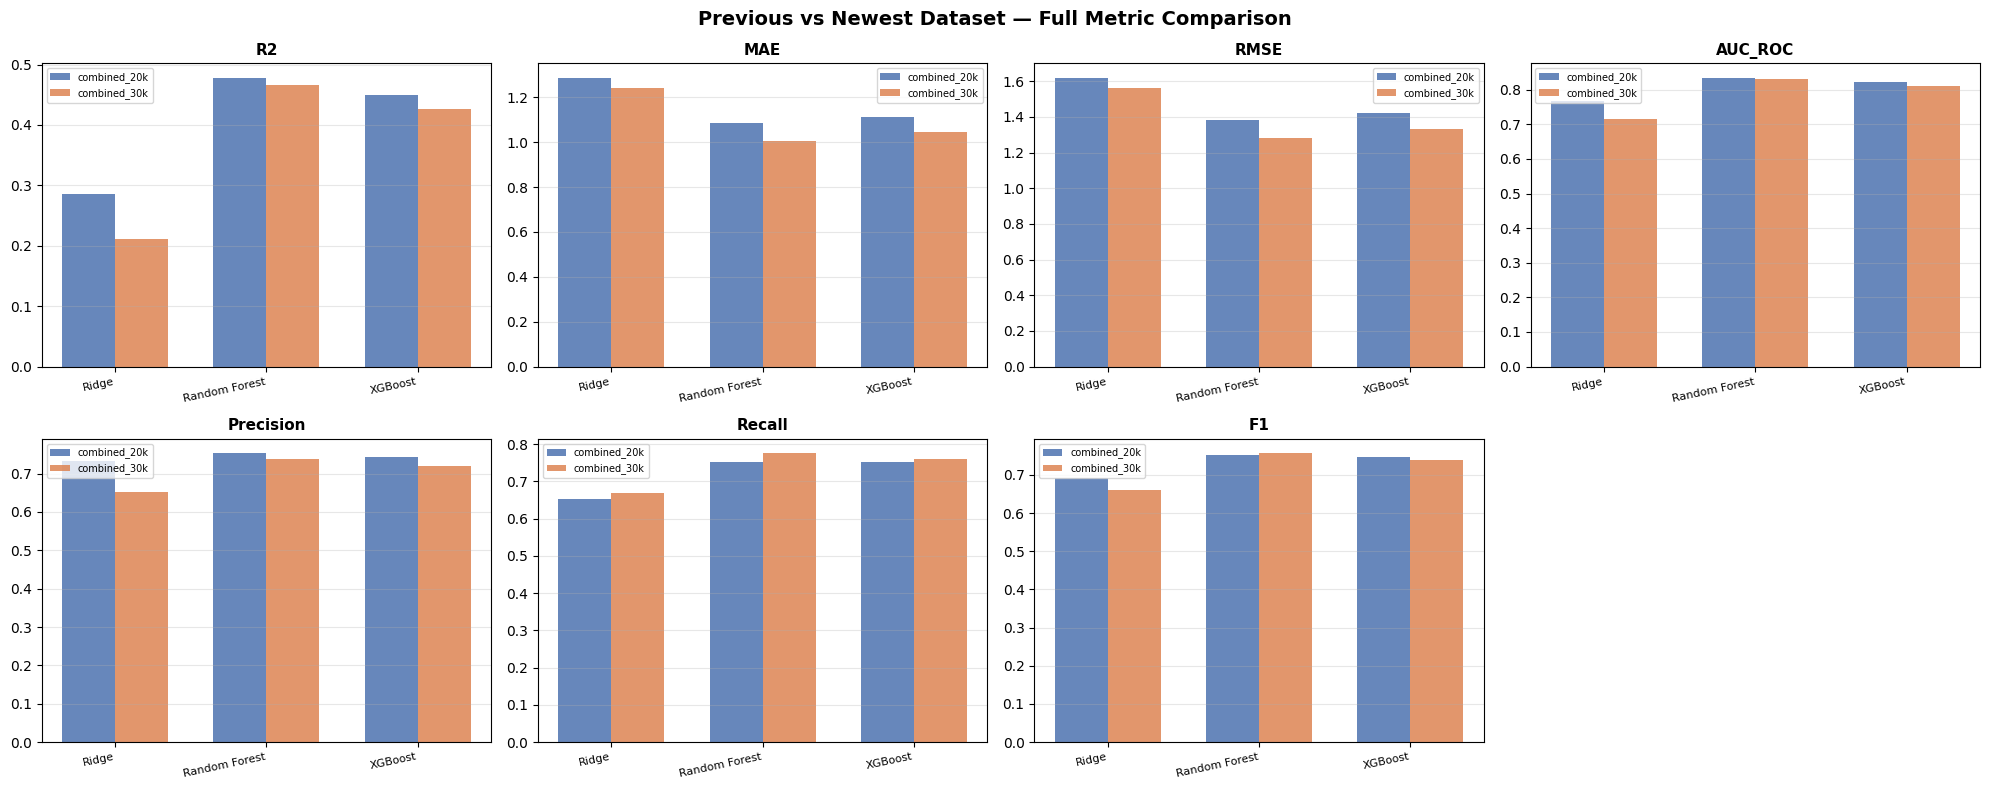

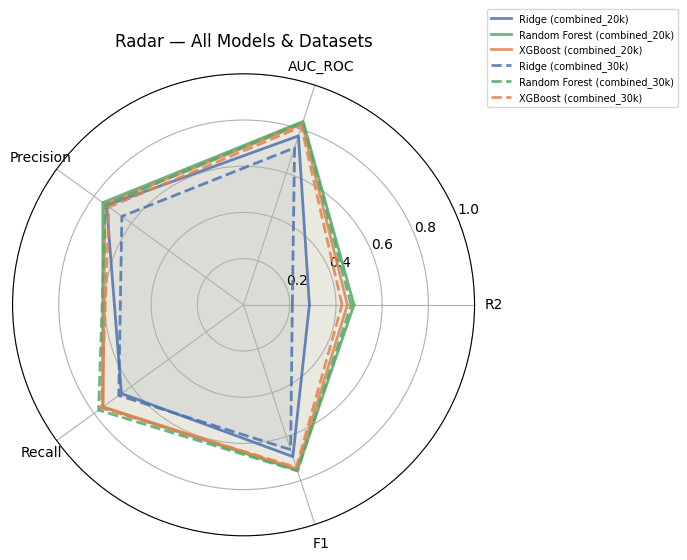

In [29]:
# ── Side-by-side bar charts ────────────────────────────────────────────────
model_names = list(res_prev.keys())
x = np.arange(len(model_names))
w = 0.35

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for idx, metric in enumerate(METRIC_COLS):
    ax = axes[idx]
    vals_p = [res_prev[n][metric] for n in model_names]
    vals_n = [res_new[n][metric]  for n in model_names]
    ax.bar(x - w/2, vals_p, w, label=label_prev, color="#4C72B0", alpha=0.85)
    ax.bar(x + w/2, vals_n, w, label=label_new,  color="#DD8452", alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(model_names, rotation=12, ha="right", fontsize=8)
    ax.set_title(metric, fontsize=11, fontweight="bold")
    ax.legend(fontsize=7); ax.grid(axis="y", alpha=0.3)

# Radar chart in last subplot
ax = axes[7]
ax.axis("off")
radar_metrics = ["R2", "AUC_ROC", "Precision", "Recall", "F1"]
n_rm = len(radar_metrics)
angles = np.linspace(0, 2*np.pi, n_rm, endpoint=False).tolist() + [0]

fig_r, ax_r = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
line_styles = [("-", label_prev), ("--", label_new)]
all_res = [res_prev, res_new]
for res_dict, (ls, lbl) in zip(all_res, line_styles):
    for name, color in MODEL_COLORS.items():
        vals = [res_dict[name][m] for m in radar_metrics] + [res_dict[name][radar_metrics[0]]]
        ax_r.plot(angles, vals, ls, color=color, linewidth=2,
                  label=f"{name} ({lbl})", alpha=0.85)
        ax_r.fill(angles, vals, color=color, alpha=0.05)
ax_r.set_thetagrids(np.degrees(angles[:-1]), radar_metrics)
ax_r.set_ylim(0, 1)
ax_r.set_title("Radar — All Models & Datasets", pad=20)
ax_r.legend(loc="upper right", bbox_to_anchor=(1.45, 1.15), fontsize=7)

fig.suptitle("Previous vs Newest Dataset — Full Metric Comparison", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()
fig_r.tight_layout()
plt.show()


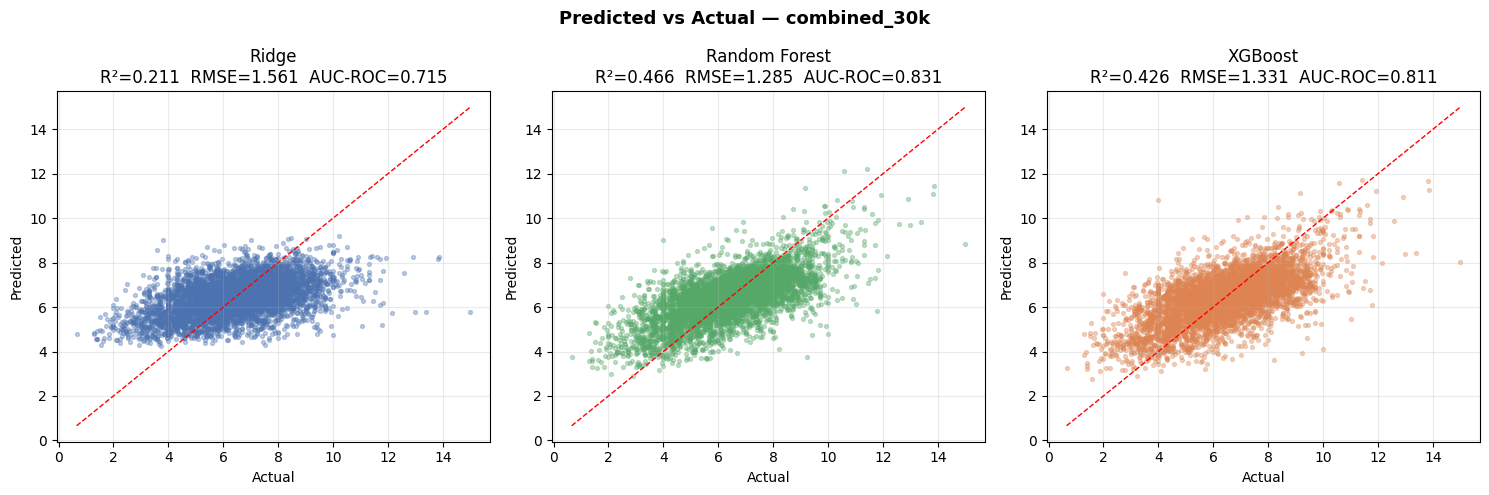

In [30]:
# ── Predicted vs Actual — newest dataset ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, color) in zip(axes, MODEL_COLORS.items()):
    r = res_new[name]
    ax.scatter(r["y_test"], r["preds"], alpha=0.35, s=8, color=color)
    lims = [min(r["y_test"].min(), r["preds"].min()),
            max(r["y_test"].max(), r["preds"].max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Actual"); ax.set_ylabel("Predicted")
    ax.set_title(f"{name}\nR²={r['R2']:.3f}  RMSE={r['RMSE']:.3f}  AUC-ROC={r['AUC_ROC']:.3f}")
    ax.grid(alpha=0.25)
fig.suptitle(f"Predicted vs Actual — {label_new}", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


## 4. iptm Threshold Sweep
Sweep from 0.0 → 0.90 on the newest dataset to find the threshold that maximises model R². Also tracks sample retention so you can weigh performance vs data volume.

In [31]:
print("Loading raw (unfiltered) newest dataset for sweep...")
df_raw = pd.read_csv(NEW_CSV, sep=None, engine="python")
print(f"  Raw rows: {len(df_raw):,}")

thresholds   = np.arange(0.0, 0.91, IPTM_SWEEP_STEP)
sweep_records = []

for thresh in thresholds:
    df_t = df_raw[df_raw["iptm"] >= thresh][FEATURES + [TARGET_COL]].dropna(subset=[TARGET_COL])
    n = len(df_t)
    if n < MIN_SAMPLES:
        print(f"  iptm≥{thresh:.2f}: {n} samples — skipping (< {MIN_SAMPLES})")
        continue

    imp_s = SimpleImputer(strategy="median")
    X_s   = pd.DataFrame(imp_s.fit_transform(df_t[FEATURES]), columns=FEATURES)
    y_s   = df_t[TARGET_COL].values

    X_tr, X_te, y_tr, y_te = train_test_split(X_s, y_s, test_size=TEST_SIZE,
                                               random_state=RANDOM_SEED)
    rec = {"iptm_threshold": thresh, "n_samples": n}
    for name, mdl in make_models().items():
        mdl.fit(X_tr, y_tr)
        rec[name] = r2_score(y_te, mdl.predict(X_te))
    sweep_records.append(rec)
    print(f"  iptm≥{thresh:.2f}  n={n:>6,}  RF={rec['Random Forest']:.3f}"
          f"  XGB={rec['XGBoost']:.3f}  Ridge={rec['Ridge']:.3f}")

sweep_df = pd.DataFrame(sweep_records)
print("\nSweep complete.")


Loading raw (unfiltered) newest dataset for sweep...
  Raw rows: 29,411
  iptm≥0.00  n=29,411  RF=0.456  XGB=0.416  Ridge=0.185
  iptm≥0.10  n=29,411  RF=0.456  XGB=0.416  Ridge=0.185
  iptm≥0.20  n=29,411  RF=0.456  XGB=0.416  Ridge=0.185
  iptm≥0.30  n=29,405  RF=0.461  XGB=0.422  Ridge=0.175
  iptm≥0.40  n=29,376  RF=0.475  XGB=0.434  Ridge=0.199
  iptm≥0.50  n=29,270  RF=0.463  XGB=0.419  Ridge=0.183
  iptm≥0.60  n=28,772  RF=0.460  XGB=0.413  Ridge=0.176
  iptm≥0.70  n=27,003  RF=0.449  XGB=0.408  Ridge=0.182
  iptm≥0.80  n=23,783  RF=0.456  XGB=0.420  Ridge=0.193
  iptm≥0.90  n=18,460  RF=0.451  XGB=0.426  Ridge=0.202

Sweep complete.


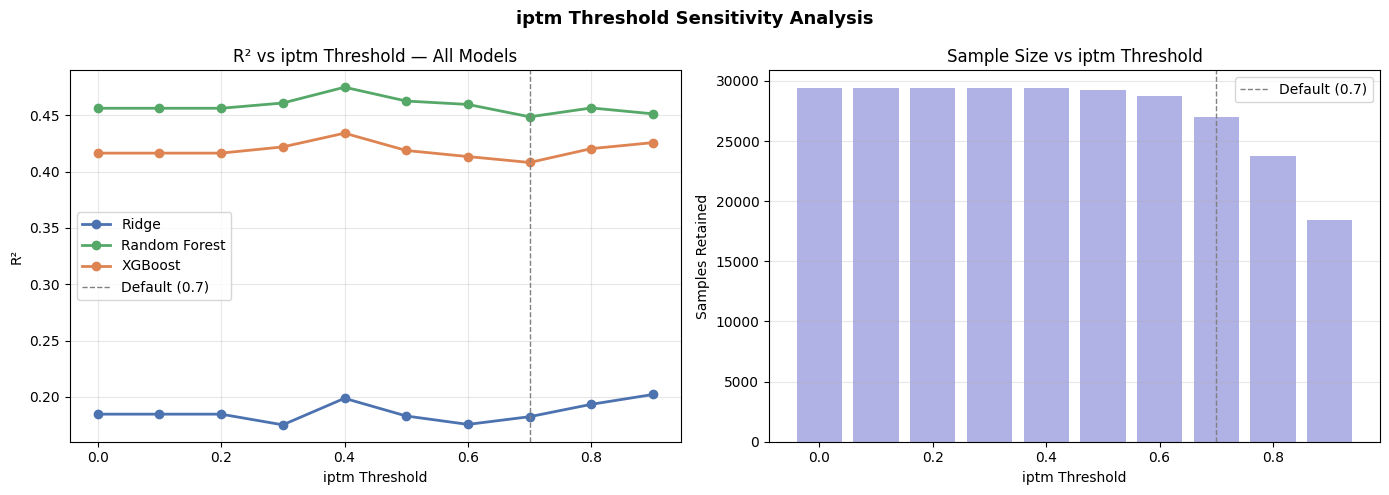


Optimal threshold per model:
            Ridge: best R²=0.2021 at iptm≥0.90  (n=18,460)
    Random Forest: best R²=0.4748 at iptm≥0.40  (n=29,376)
          XGBoost: best R²=0.4340 at iptm≥0.40  (n=29,376)

→ Using iptm≥0.40 (Random Forest optimum) for tuning section.


In [32]:
# ── Plot: R² and sample size vs threshold ─────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, color in MODEL_COLORS.items():
    ax1.plot(sweep_df["iptm_threshold"], sweep_df[name],
             "o-", label=name, color=color, linewidth=2, markersize=6)
ax1.axvline(IPTM_DEFAULT, color="gray", linestyle="--", linewidth=1,
            label=f"Default ({IPTM_DEFAULT})")
ax1.set_xlabel("iptm Threshold"); ax1.set_ylabel("R²")
ax1.set_title("R² vs iptm Threshold — All Models")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.bar(sweep_df["iptm_threshold"], sweep_df["n_samples"],
        width=IPTM_SWEEP_STEP * 0.8, color="#9C9EDE", alpha=0.8)
ax2.axvline(IPTM_DEFAULT, color="gray", linestyle="--", linewidth=1,
            label=f"Default ({IPTM_DEFAULT})")
ax2.set_xlabel("iptm Threshold"); ax2.set_ylabel("Samples Retained")
ax2.set_title("Sample Size vs iptm Threshold")
ax2.legend(); ax2.grid(axis="y", alpha=0.3)

fig.suptitle("iptm Threshold Sensitivity Analysis", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# ── Best threshold per model ───────────────────────────────────────────────
print("\nOptimal threshold per model:")
for name in MODEL_COLORS:
    best = sweep_df.loc[sweep_df[name].idxmax()]
    print(f"  {name:>15}: best R²={best[name]:.4f} at iptm≥{best['iptm_threshold']:.2f}"
          f"  (n={int(best['n_samples']):,})")

best_thresh_rf = sweep_df.loc[sweep_df["Random Forest"].idxmax(), "iptm_threshold"]
print(f"\n→ Using iptm≥{best_thresh_rf:.2f} (Random Forest optimum) for tuning section.")


## 5. Best Model — Cross-Validation & Hyperparameter Tuning
Identify the best model from Section 3, reload the newest dataset at the optimal iptm threshold, then run 5-fold CV and RandomizedSearchCV.

In [ ]:
# ── Identify best model on newest dataset ─────────────────────────────────
best_model_name = max(res_new, key=lambda k: res_new[k]["R2"])
print(f"Best model (newest dataset, default iptm): "
      f"{best_model_name}  R²={res_new[best_model_name]['R2']:.4f}")

# ── Reload with optimal iptm threshold ────────────────────────────────────
if best_thresh_rf < IPTM_DEFAULT:
    best_thresh_rf == IPTM_DEFAULT
print(f"\nReloading {NEW_CSV} with iptm≥{best_thresh_rf:.2f} ...")
X_opt, y_opt, imp_opt = load_dataset(NEW_CSV, iptm_thresh=best_thresh_rf)
print(f"  Samples after optimal filter: {len(X_opt):,}")

X_tr_opt, X_te_opt, y_tr_opt, y_te_opt = train_test_split(
    X_opt, y_opt, test_size=TEST_SIZE, random_state=RANDOM_SEED)


Best model (newest dataset, default iptm): Random Forest  R²=0.4654

Reloading combined_30k.csv with iptm≥0.40 ...
  Samples after optimal filter: 29,376


=== Random Forest — 5-fold CV at optimal iptm≥0.40 ===
  Train R²  : 0.9263 ± 0.0018
  Test  R²  : 0.3486 ± 0.1025
  Test  MAE : 1.1133
  Test  RMSE: 1.4026


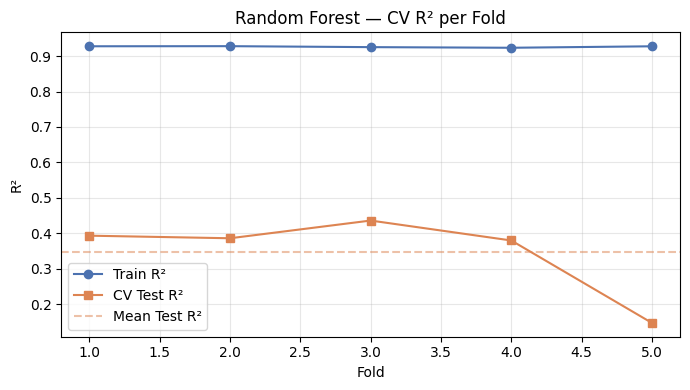

In [12]:
# ── 5-fold Cross-Validation (base model) ─────────────────────────────────
print(f"=== {best_model_name} — 5-fold CV at optimal iptm≥{best_thresh_rf:.2f} ===")

base_for_cv = make_models()[best_model_name]

cv_res = cross_validate(
    base_for_cv, X_opt, y_opt, cv=5,
    scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"],
    return_train_score=True, n_jobs=-1
)

print(f"  Train R²  : {cv_res['train_r2'].mean():.4f} ± {cv_res['train_r2'].std():.4f}")
print(f"  Test  R²  : {cv_res['test_r2'].mean():.4f} ± {cv_res['test_r2'].std():.4f}")
print(f"  Test  MAE : {-cv_res['test_neg_mean_absolute_error'].mean():.4f}")
print(f"  Test  RMSE: {-cv_res['test_neg_root_mean_squared_error'].mean():.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
folds = range(1, 6)
ax.plot(folds, cv_res["train_r2"], "o-", label="Train R²", color="#4C72B0")
ax.plot(folds, cv_res["test_r2"],  "s-", label="CV Test R²", color="#DD8452")
ax.axhline(cv_res["test_r2"].mean(), color="#DD8452", linestyle="--",
           alpha=0.5, label="Mean Test R²")
ax.set_xlabel("Fold"); ax.set_ylabel("R²")
ax.set_title(f"{best_model_name} — CV R² per Fold"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [13]:
# ── RandomizedSearchCV ────────────────────────────────────────────────────
print(f"Running RandomizedSearchCV for {best_model_name} (30 iterations, 5-fold)...")

# Param grids keyed by model name
param_grids = {
    "Random Forest": {
        "n_estimators":      [100, 200, 300, 500],
        "max_depth":         [None, 10, 20, 30],
        "max_features":      ["sqrt", "log2", 0.5],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf":  [1, 2, 4],
        "bootstrap":         [True, False],
    },
    "XGBoost": {
        "n_estimators":     [300, 500, 800],
        "max_depth":        [4, 6, 8],
        "learning_rate":    [0.01, 0.05, 0.1],
        "subsample":        [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "gamma":            [0, 0.1, 0.3],
    },
    "Ridge": {
        "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0],
    },
}

base_estimator = make_models()[best_model_name]
search = RandomizedSearchCV(
    base_estimator,
    param_grids[best_model_name],
    n_iter=30, cv=5, scoring="r2",
    random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
search.fit(X_tr_opt, y_tr_opt)

print(f"\nBest CV R²  : {search.best_score_:.4f}")
print(f"Best params : {search.best_params_}")


Running RandomizedSearchCV for Random Forest (30 iterations, 5-fold)...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best CV R²  : 0.4505
Best params : {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None, 'bootstrap': False}


In [14]:
# ── Compare base vs tuned on held-out test set ────────────────────────────
base_mdl = make_models()[best_model_name]
base_mdl.fit(X_tr_opt, y_tr_opt)
base_preds  = base_mdl.predict(X_te_opt)
tuned_preds = search.best_estimator_.predict(X_te_opt)

m_base  = compute_metrics(y_te_opt, base_preds)
m_tuned = compute_metrics(y_te_opt, tuned_preds)

comp_df = pd.DataFrame(
    [{"Version": "Base",  **m_base},
     {"Version": "Tuned", **m_tuned}]
).set_index("Version")

print(f"=== {best_model_name}: Base vs Tuned (optimal iptm≥{best_thresh_rf:.2f}) ===")
display(comp_df.round(4))

# Delta row
delta = comp_df.loc["Tuned"] - comp_df.loc["Base"]
print("\nΔ (Tuned − Base):")
print(delta.round(4).to_string())


=== Random Forest: Base vs Tuned (optimal iptm≥0.40) ===


,R2,MAE,RMSE,AUC_ROC,Precision,Recall,F1
Version,,,,,,,
Base,0.4748,1.0154,1.3021,0.8338,0.7429,0.7621,0.7523
Tuned,0.4844,1.0003,1.2902,0.8372,0.7540,0.7658,0.7599



Δ (Tuned − Base):
R2           0.0096
MAE         -0.0151
RMSE        -0.0119
AUC_ROC      0.0034
Precision    0.0111
Recall       0.0037
F1           0.0075


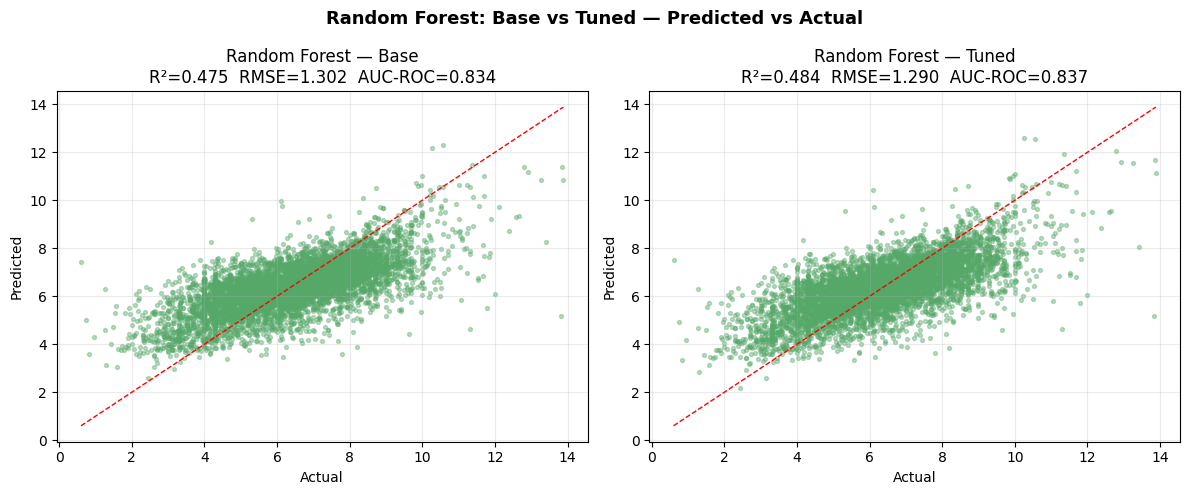

In [15]:
# ── Predicted vs Actual: Base vs Tuned ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
best_color = MODEL_COLORS[best_model_name]

for ax, (preds, label, alpha) in zip(axes, [
    (base_preds,  f"{best_model_name} — Base",  0.40),
    (tuned_preds, f"{best_model_name} — Tuned", 0.40),
]):
    m = compute_metrics(y_te_opt, preds)
    ax.scatter(y_te_opt, preds, alpha=alpha, s=8, color=best_color)
    lims = [min(y_te_opt.min(), preds.min()), max(y_te_opt.max(), preds.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Actual"); ax.set_ylabel("Predicted")
    ax.set_title(f"{label}\nR²={m['R2']:.3f}  RMSE={m['RMSE']:.3f}  AUC-ROC={m['AUC_ROC']:.3f}")
    ax.grid(alpha=0.25)

fig.suptitle(f"{best_model_name}: Base vs Tuned — Predicted vs Actual",
             fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()


## 6. Feature Importance & SHAP
Feature importances from tree models, plus SHAP values for the tuned best model.

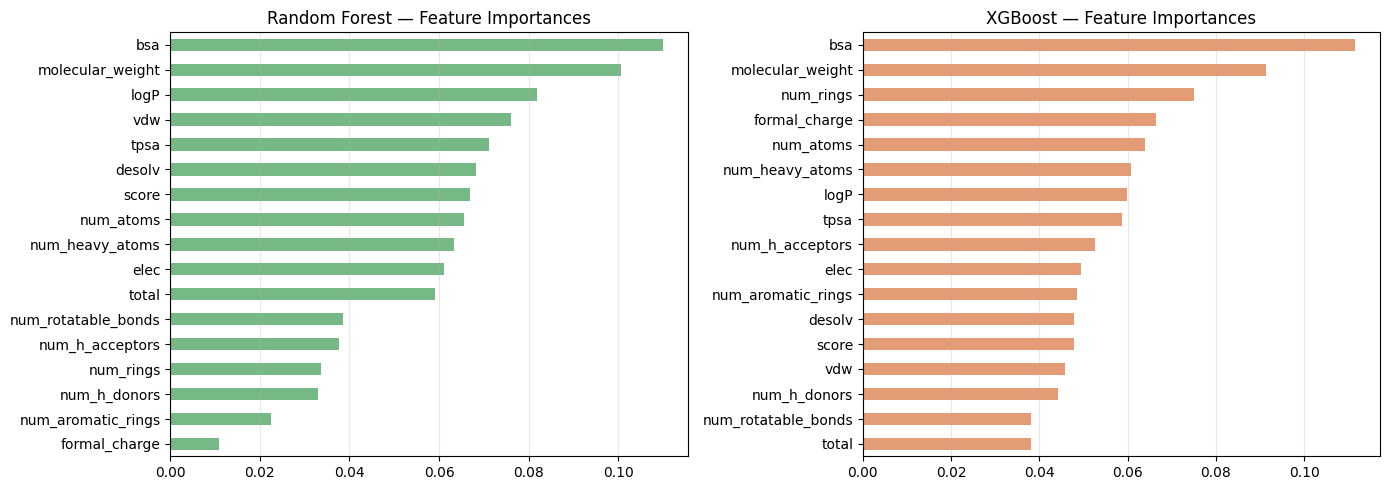

In [16]:
# ── Feature importance (RF and XGBoost from newest dataset) ───────────────
tree_models = {k: res_new[k]["model"] for k in ["Random Forest", "XGBoost"]}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, mdl) in zip(axes, tree_models.items()):
    estimator = mdl.named_steps["model"] if hasattr(mdl, "named_steps") else mdl
    imp = pd.Series(estimator.feature_importances_, index=FEATURES).sort_values()
    imp.plot(kind="barh", ax=ax, color=MODEL_COLORS[name], alpha=0.8)
    ax.set_title(f"{name} — Feature Importances"); ax.grid(axis="x", alpha=0.3)

plt.tight_layout(); plt.show()


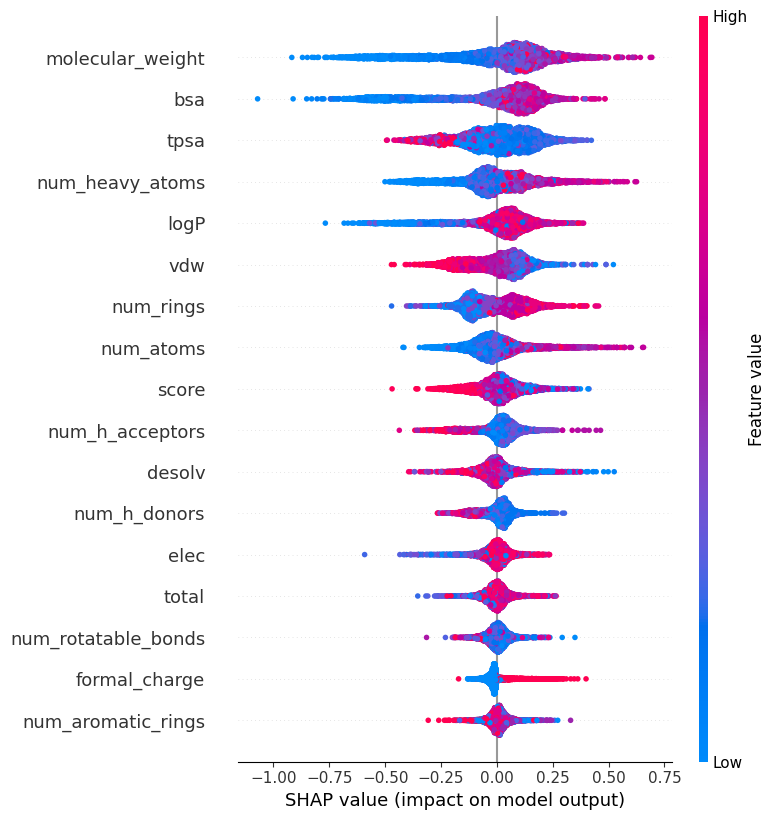

In [17]:
# ── SHAP for tuned best model ─────────────────────────────────────────────
import shap

tuned_estimator = (search.best_estimator_.named_steps["model"]
                   if hasattr(search.best_estimator_, "named_steps")
                   else search.best_estimator_)

explainer   = shap.TreeExplainer(tuned_estimator)
shap_values = explainer.shap_values(X_te_opt)

shap.summary_plot(shap_values, X_te_opt, feature_names=FEATURES, show=True)


## 7. Save Best Model

In [18]:
out_path = f"tuned_{best_model_name.lower().replace(' ', '_')}_best.pkl"
joblib.dump(search.best_estimator_, out_path)
joblib.dump(imp_opt, out_path.replace(".pkl", "_imputer.pkl"))
print(f"Saved → {out_path}")
print(f"       → {out_path.replace('.pkl', '_imputer.pkl')}")
print(f"\nFinal metrics (tuned, optimal iptm≥{best_thresh_rf:.2f}):")
print(comp_df.loc[["Tuned"]].round(4).to_string())


Saved → tuned_random_forest_best.pkl
       → tuned_random_forest_best_imputer.pkl

Final metrics (tuned, optimal iptm≥0.40):
             R2     MAE    RMSE  AUC_ROC  Precision  Recall      F1
Version                                                            
Tuned    0.4844  1.0003  1.2902   0.8372      0.754  0.7658  0.7599


## 8. Predict on New Compounds

In [ ]:
# new_df  = pd.read_csv("new_compounds.csv", sep=None, engine="python")
# X_new   = pd.DataFrame(imp_opt.transform(new_df[FEATURES]), columns=FEATURES)
# model   = joblib.load(out_path)
# new_df[f"predicted_{TARGET_COL}"] = model.predict(X_new)
# new_df.to_csv("predictions.csv", index=False)
# display(new_df.head())
